In [1]:
import os
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
import sys
sys.path.append('/home/diogo/miniforge3/envs/core_neuron/lib/python')
from neuron import h

# Fig 1 Trace

In [2]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 1000.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig1']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1

delaystim = 300
durationstim = 400

cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.5}     

#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [3]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig1
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig1_template.hoc
Exists: True
Creating a generic Fig1 cell from Pospischil2008 template
{geom: {L: 96.0, nseg: 1, diam: 96.0, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {hh2: {gnabar: 0.05, gkbar: 0.005, vtraub: -55.0}, im: {gkbar: 7e-05}, pas: {g: 1e-05, e: -75.0}}, ions: {k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}}


In [4]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:20.593577




Creating network of 1 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 1 
  Done; cell creation time = 0.00 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 1 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 1000.0 ms...
0.5s
1.0s
  Done; run time = 0.03 s; real-time ratio: 37.94.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 11 (11.00 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 0.03 s
   pop_Fig1 : 11.000 Hz
  Done; plotting time = 0.00 s

Total time = 0.03 s


Text(0.5, 0, 'Time (ms)')

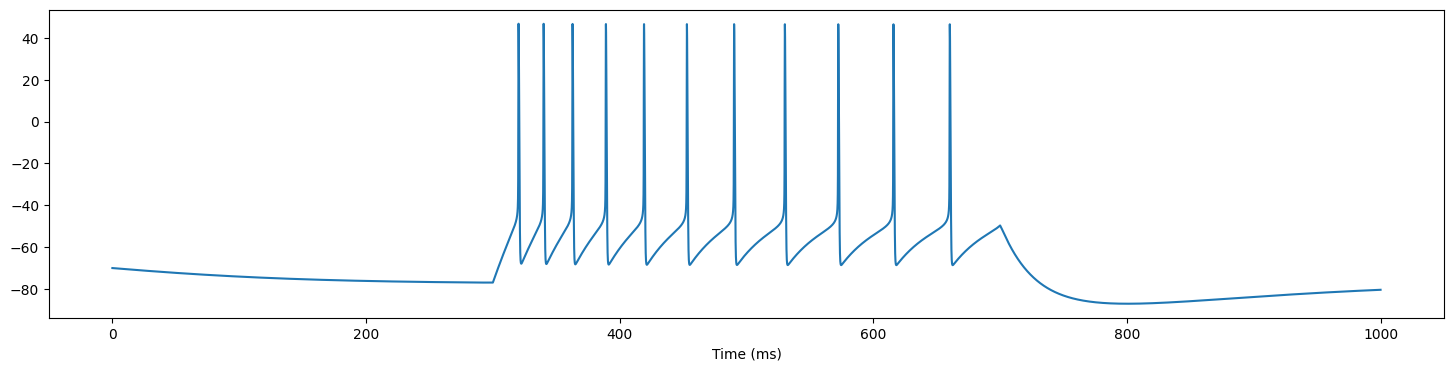

In [5]:
data = sim.allSimData
time = np.linspace(0,cfg.duration, len(data['V_soma']['cell_0']))
plt.figure(figsize=(18,4))
plt.plot(time, data['V_soma']['cell_0'])
plt.xlabel('Time (ms)')

# Fig 2 Traces A and B

In [6]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 1000.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig2A', 'Fig2B']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1

delaystim = 300
durationstim = 400

cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.4}  
cfg.IClamp1 =   {'pop': cfg.allpops[1], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.4}   


#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [7]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig2A
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig2A_template.hoc
Exists: True
Creating a generic Fig2A cell from Pospischil2008 template
{geom: {L: 61.4, nseg: 1, diam: 61.4, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {hh2: {gnabar: 0.056, gkbar: 0.006, vtraub: -56.2}, im: {gkbar: 7.5e-05}, pas: {g: 2.05e-05, e: -70.3}}, ions: {k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}, vinit: -70.0}
Loading cell: Fig2B
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig2B_template.hoc
Exists: True
Creating a generic Fig2B cell from Pospischil2008 template
{geom: {L: 61.8, nseg: 1, diam: 61.8, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {hh2: {gnabar: 0.01, gkbar: 0.0021, vtraub: -67.9}, im: {gkbar: 9.8e-05}, pas: {g: 1.33e-05, e: -56.2}}, ions: {k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}}


In [8]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:20.811332




Creating network of 2 cell populations on 1 hosts...: 100%|##########|


  Number of cells on node 0: 2 
  Done; cell creation time = 0.01 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 2 
  Done; cell stims creation time = 0.00 s.
Recording 2 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 1000.0 ms...
0.5s
1.0s
  Done; run time = 0.03 s; real-time ratio: 31.08.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 2
  Connections: 0 (0.00 per cell)
  Spikes: 64 (32.00 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 0.03 s
   pop_Fig2A : 24.000 Hz
   pop_Fig2B : 40.000 Hz
  Done; plotting time = 0.00 s

Total time = 0.04 s


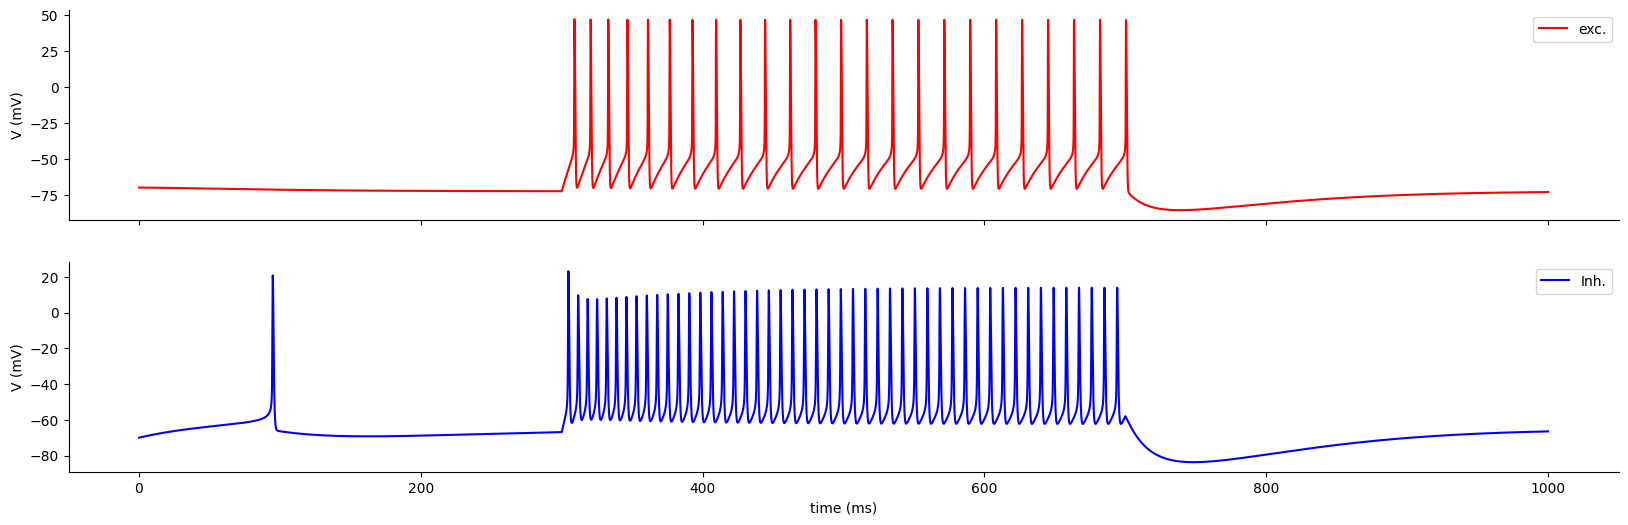

In [9]:
data = sim.allSimData
time = np.linspace(0,cfg['duration'], len(data['V_soma']['cell_0']))


fig, axes = plt.subplots(2,1, figsize = (20,6), sharex = True)

axes[0].plot(time, data['V_soma']['cell_0'], label = 'exc.', c = 'red')
axes[0].set_ylabel('V (mV)')
axes[0].legend()

axes[1].plot(time, data['V_soma']['cell_1'], label = 'Inh.', c = 'blue')
axes[1].set_ylabel('V (mV)')
axes[1].set_xlabel('time (ms)')
axes[1].legend()

sns.despine()

# Fig 3 (c)

In [10]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 1000.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig3C']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1

delaystim = 300
durationstim = 400

cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.6}  
#cfg.IClamp1 =   {'pop': cfg.allpops[1], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.4}   


#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [11]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig3C
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig3C_template.hoc
Exists: True
Creating a generic Fig3C cell from Pospischil2008 template
{geom: {L: 67.0, nseg: 1, diam: 67.0, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {hh2: {gnabar: 0.05, gkbar: 0.01, vtraub: -55.0}, pas: {g: 0.00015, e: -70.0}}, ions: {k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}, vinit: -70.0}


In [12]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:21.044553




Creating network of 1 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 1 
  Done; cell creation time = 0.00 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 1 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 1000.0 ms...
0.5s
1.0s
  Done; run time = 0.02 s; real-time ratio: 43.49.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 27 (27.00 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 0.02 s
   pop_Fig3C : 27.000 Hz
  Done; plotting time = 0.00 s

Total time = 0.03 s


Text(0.5, 0, 'Time (ms)')

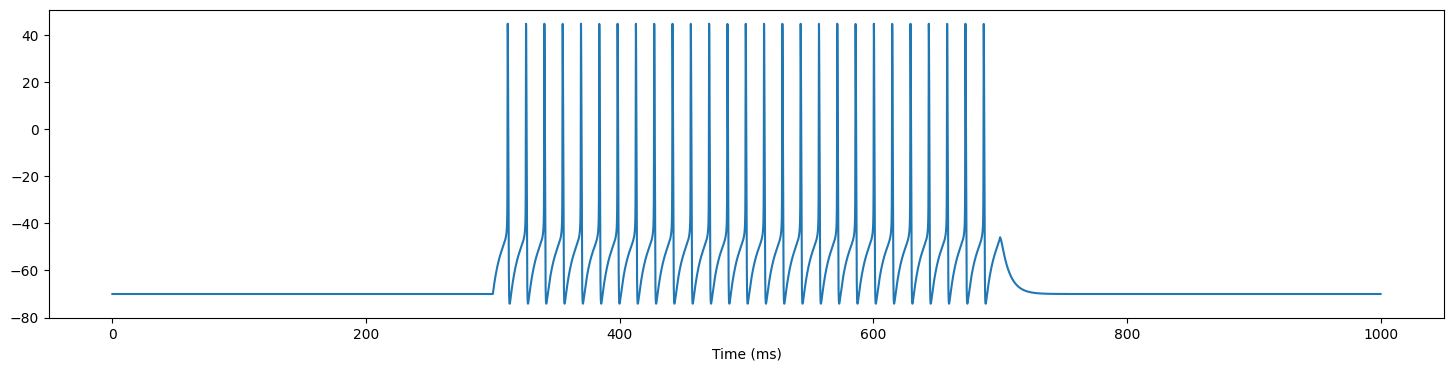

In [13]:
data = sim.allSimData
time = np.linspace(0,cfg.duration, len(data['V_soma']['cell_0']))
plt.figure(figsize=(18,4))
plt.plot(time, data['V_soma']['cell_0'])
plt.xlabel('Time (ms)')

# Fig 4

In [14]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 1000.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig4']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1

delaystim = 300
durationstim = 400

cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.6}  
#cfg.IClamp1 =   {'pop': cfg.allpops[1], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.4}   


#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [15]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig4
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig4_template.hoc
Exists: True
Creating a generic Fig4 cell from Pospischil2008 template
{geom: {L: 56.9, nseg: 1, diam: 56.9, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {hh2: {gnabar: 0.058, gkbar: 0.0039, vtraub: -57.9}, im: {gkbar: 7.87e-05}, pas: {g: 3.8e-05, e: -70.4}}, ions: {k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}, vinit: -70.0}


In [16]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:21.202063




Creating network of 1 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 1 
  Done; cell creation time = 0.00 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 1 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 1000.0 ms...
0.5s
1.0s
  Done; run time = 0.03 s; real-time ratio: 36.76.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 46 (46.00 Hz)
  Simulated time: 1.0 s; 1 workers
  Run time: 0.03 s
   pop_Fig4 : 46.000 Hz
  Done; plotting time = 0.00 s

Total time = 0.03 s


Text(0.5, 0, 'Time (ms)')

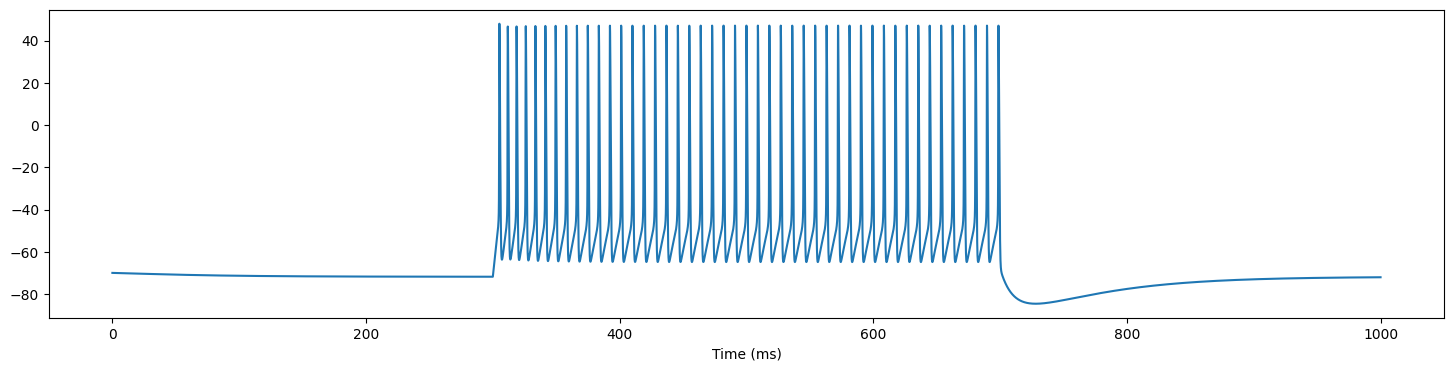

In [17]:
data = sim.allSimData
time = np.linspace(0,cfg.duration, len(data['V_soma']['cell_0']))
plt.figure(figsize=(18,4))
plt.plot(time, data['V_soma']['cell_0'])
plt.xlabel('Time (ms)')

# Fig 5

In [18]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 1800.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig5B1', 'Fig5B2']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1

delaystim = 500
durationstim = 1000

cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.15}  
cfg.IClamp1 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': 0.0, 'dur': 500.0, 'amp': -0.04}

cfg.IClamp2 =   {'pop': cfg.allpops[1], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.15}  
cfg.IClamp3 =   {'pop': cfg.allpops[1], 'sec': 'soma', 'loc': 0.5, 'start': 0.0, 'dur': 500.0, 'amp': -0.04}


#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [19]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig5B1
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig5B1_template.hoc
Exists: True
Creating a generic Fig5B1 cell from Pospischil2008 template
{geom: {L: 96.0, nseg: 1, diam: 96.0, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {cad: {depth: 1.0, taur: 5.0, cainf: 0.00024, kt: 0.0, kd: 0.0}, hh2: {gnabar: 0.05, gkbar: 0.005, vtraub: -55.0}, ical: {gcabar: 0.00018}, im: {gkbar: 3e-05}, pas: {g: 1e-05, e: -70.0}}, ions: {ca: {e: 120.0, i: 0.00024, o: 2.0}, k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}, vinit: -70.0}
Loading cell: Fig5B2
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig5B2_template.hoc
Exists: True
Creating a generic Fig5B2 cell from Pospischil2008 template
{geom: {L: 96.0, nseg: 1, diam: 96.0, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {cad: {depth: 1.0, taur: 5.0, cainf: 0.00024, kt: 0.0, kd: 0.0}, hh2: {gnabar: 0.05, gkbar: 0.005, vtraub: -55.0}, ical: {gcabar: 0.00024}, im: {gkbar: 3e-05}, pas: {g: 1e-05, e: -70.0}}, ions: {ca: {e: 120.0, i: 

In [20]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:21.424906




Creating network of 2 cell populations on 1 hosts...: 100%|##########|


  Number of cells on node 0: 2 
  Done; cell creation time = 0.01 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 4 
  Done; cell stims creation time = 0.00 s.
Recording 2 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 1800.0 ms...
0.5s
1.0s
1.5s
  Done; run time = 0.09 s; real-time ratio: 21.16.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 2
  Connections: 0 (0.00 per cell)
  Spikes: 36 (10.00 Hz)
  Simulated time: 1.8 s; 1 workers
  Run time: 0.09 s
   pop_Fig5B1 : 5.556 Hz
   pop_Fig5B2 : 14.444 Hz
  Done; plotting time = 0.00 s

Total time = 0.09 s


Text(0.5, 0, 'Time (ms)')

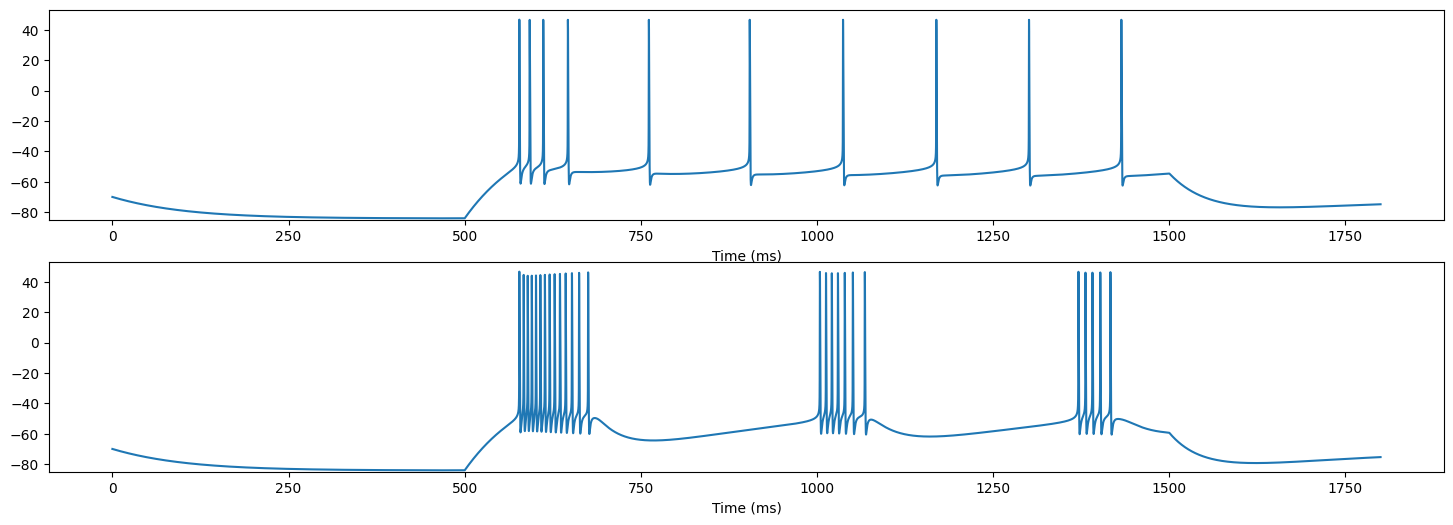

In [21]:
data = sim.allSimData
time = np.linspace(0,cfg.duration, len(data['V_soma']['cell_0']))

fig, axes = plt.subplots(2,1, figsize=(18,6))

axes[0].plot(time, data['V_soma']['cell_0'])
axes[0].set_ylim(-85,)
axes[0].set_xlabel('Time (ms)')

axes[1].plot(time, data['V_soma']['cell_1'])
axes[1].set_ylim(-85,)
axes[1].set_xlabel('Time (ms)')

# Fig 6

In [22]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 1800.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig6B']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1

delaystim = 500
durationstim = 1000

cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.7}  
#cfg.IClamp1 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': 0.0, 'dur': 500.0, 'amp': -0.04}


#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [23]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig6B
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig6B_template.hoc
Exists: True
Creating a generic Fig6B cell from Pospischil2008 template
{geom: {L: 96.0, nseg: 1, diam: 96.0, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {cad: {depth: 1.0, taur: 5.0, cainf: 0.00024, kt: 0.0, kd: 0.0}, hh2: {gnabar: 0.05, gkbar: 0.0042, vtraub: -58.0}, ical: {gcabar: 0.0002}, im: {gkbar: 4.2e-05}, pas: {g: 0.0001, e: -75.0}}, ions: {ca: {e: 120.0, i: 0.00024, o: 2.0}, k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}, vinit: -70.0}


In [24]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:21.705677




Creating network of 1 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 1 
  Done; cell creation time = 0.00 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 1 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 1800.0 ms...
0.5s
1.0s
1.5s
  Done; run time = 0.07 s; real-time ratio: 26.67.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 10 (5.56 Hz)
  Simulated time: 1.8 s; 1 workers
  Run time: 0.07 s
   pop_Fig6B : 5.556 Hz
  Done; plotting time = 0.00 s

Total time = 0.07 s


Text(0.5, 0, 'Time (ms)')

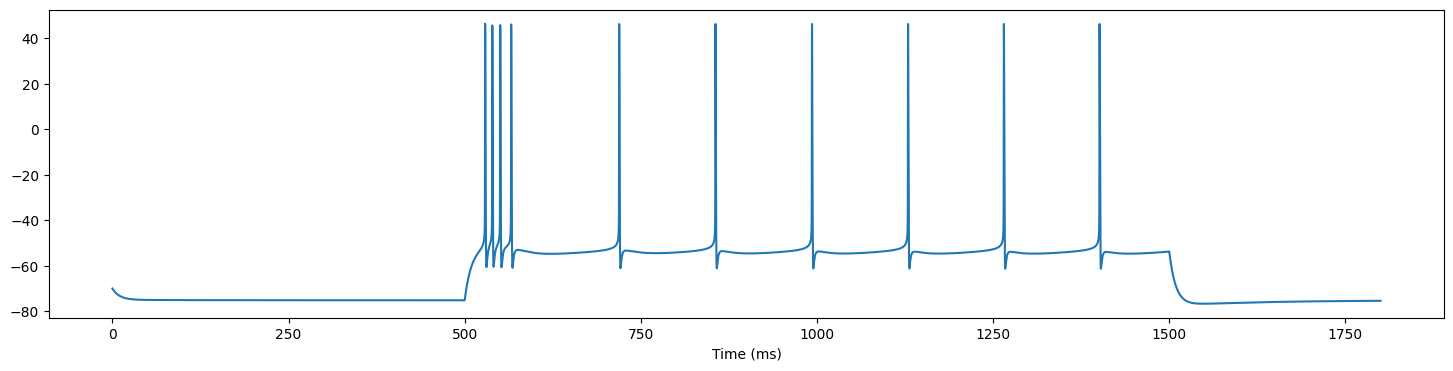

In [25]:
data = sim.allSimData
time = np.linspace(0,cfg.duration, len(data['V_soma']['cell_0']))
plt.figure(figsize=(18,4))
plt.plot(time, data['V_soma']['cell_0'])
plt.xlabel('Time (ms)')

# Fig 8

In [26]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 2500.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig8']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1

panel = 'c' # b c

if panel == 'a':
    cfg.IClamp1 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': 1000.0, 'dur': 1000.0, 'amp': -0.1} # PANEL A

if panel == 'b':
    delaystim = 1000
    durationstim = 1000
    cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.1}   # PANEL B

if panel == 'c':
    cfg.duration = 3500.0 ## Duration of the sim, in ms
    delaystim = 2000
    durationstim = 1000
    cfg.IClamp1 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': 1000.0, 'dur': 1000.0, 'amp': -0.1} # PANEL A
    cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.1}   # PANEL B



#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [27]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig8
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig8_template.hoc
Exists: True
Creating a generic Fig8 cell from Pospischil2008 template
{geom: {L: 96.0, nseg: 1, diam: 96.0, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {cad: {depth: 1.0, taur: 5.0, cainf: 0.00024, kt: 0.0, kd: 0.0}, hh2: {gnabar: 0.05, gkbar: 0.005, vtraub: -55.0}, im: {gkbar: 3e-05}, it: {gcabar: 0.0004, shift: 2.0}, pas: {g: 1e-05, e: -70.0}}, ions: {ca: {e: 120.0, i: 0.00024, o: 2.0}, k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}, vinit: -70.0}


In [28]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:21.912784




Creating network of 1 cell populations on 1 hosts...: 100%|##########|


  Number of cells on node 0: 1 
  Done; cell creation time = 0.00 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 2 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 3500.0 ms...
0.5s
1.0s
1.5s
2.0s
2.5s
3.0s
3.5s
  Done; run time = 0.13 s; real-time ratio: 26.74.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 6 (1.71 Hz)
  Simulated time: 3.5 s; 1 workers
  Run time: 0.13 s
   pop_Fig8 : 1.714 Hz
  Done; plotting time = 0.00 s

Total time = 0.14 s


Text(0.5, 0, 'Time (ms)')

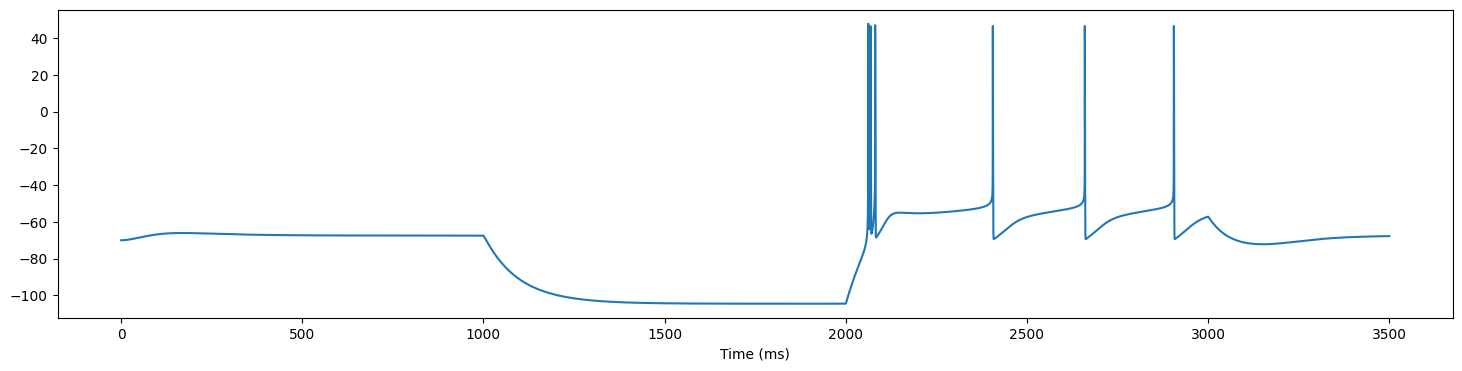

In [29]:
data = sim.allSimData
time = np.linspace(0,cfg.duration, len(data['V_soma']['cell_0']))
plt.figure(figsize=(18,4))
plt.plot(time, data['V_soma']['cell_0'])
plt.xlabel('Time (ms)')

# Fig 9

In [30]:
"""
cfg.py 
Contributors: diogoleonaisouza@gmail.com, fernandodasilvaborges@gmail.com
"""

from netpyne import specs

cfg = specs.SimConfig()     

#------------------------------------------------------------------------------
# SIMULATION CONFIGURATION
#------------------------------------------------------------------------------

cfg.coreneuron = False

rootFolder = os.getcwd()

#------------------------------------------------------------------------------
# Run parameters
#------------------------------------------------------------------------------

cfg.duration = 3500.0 ## Duration of the sim, in ms  
cfg.dt = 0.025
# ~ cfg.seeds = {'conn': 4321, 'stim': 1234, 'loc': 4321} 
cfg.hParams = {'celsius': 36, 'v_init': -70}  
cfg.verbose = False
cfg.createNEURONObj = True
cfg.createPyStruct = True
cfg.cvode_active = False
cfg.cvode_atol = 1e-6
cfg.cache_efficient = True
cfg.printRunTime = 0.5

cfg.includeParamsLabel = False
cfg.printPopAvgRates = True
cfg.checkErrors = False

cfg.allpops = []
cfg.allcells = ['Fig9']

for cell in cfg.allcells:
    cfg.allpops.append(f'pop_{cell}')

#------------------------------------------------------------------------------
# Analysis and plotting 
#------------------------------------------------------------------------------
# cfg.analysis['plotTraces'] = {'include': cfg.allpops, 'saveFig': False, 'showFig': False, 'oneFigPer':'trace', 'axis': False, 'subtitles':False, 'legend':False, 'overlay':False, 'figSize':(36, 24), 'fontSize':2}
# cfg.analysis['plot2Dnet']   = {'include': cfg.allpops, 'saveFig': True, 'showFig': False, 'showConns': True, 'figSize': (12,12), 'view': 'xz', 'fontSize':8} 

#------------------------------------------------------------------------------
# Current inputs 
#------------------------------------------------------------------------------
cfg.addIClamp = 1


delaystim = 2000
durationstim = 1000
cfg.IClamp0 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': delaystim, 'dur': durationstim, 'amp': 0.13}
cfg.IClamp1 =   {'pop': cfg.allpops[0], 'sec': 'soma', 'loc': 0.5, 'start': 1000.0, 'dur': durationstim, 'amp': -0.15}


#------------------------------------------------------------------------------
# Record Data 
#------------------------------------------------------------------------------

cfg.recordCells = cfg.allpops  # which cells to record from
cfg.recordTraces = {'V_soma': {'sec':'soma_0', 'loc':0.5, 'var':'v'}}  ## Dict with traces to record
cfg.recordStim = True
cfg.recordTime = True
cfg.recordStep = cfg.dt            

cfg.simLabel = 'v0_batch0'
cfg.saveFolder = '../data/'+cfg.simLabel
# cfg.filename =                	## Set file output name
cfg.savePickle = False         	## Save pkl file
cfg.saveJson = False           	## Save json file
cfg.saveDataInclude = ['simConfig', 'netParams', 'simData'] ## 
cfg.backupCfgFile = None 		##  
cfg.gatherOnlySimData = False	##  
cfg.saveCellSecs = False			##  
cfg.saveCellConns = True		##


#------------------------------------------------------------------------------
# Net
#------------------------------------------------------------------------------
cfg.cellNumber = 1
cfg.gex = 0.00

In [31]:
netParams = specs.NetParams()

#------------------------------------------------------------------------------
# NETWORK PARAMETERS
#------------------------------------------------------------------------------

#------------------------------------------------------------------------------
# General network parameters
#------------------------------------------------------------------------------
netParams.scale = 1.0 # Scale factor for number of cells
netParams.sizeX = 100.0 # x-dimension (horizontal length) size in um
netParams.sizeY = 100.0 # y-dimension (vertical height or cortical depth) size in um
netParams.sizeZ = 100.0 # z-dimension (horizontal depth) size in um
netParams.shape = 'cylinder' # cylindrical (column-like) volume
   
netParams.propVelocity = 300.0    # propagation velocity (um/ms)
netParams.probLengthConst = 10.0 # length constant for conn probability (um)


#------------------------------------------------------------------------------
# Cell parameters
#------------------------------------------------------------------------------
MODELS_DIR = 'models'
for cellName in cfg.allcells:


    cellRule = netParams.importCellParams(label=cellName + '_rule', somaAtOrigin=False,
        conds={'cellType': cellName, 'cellModel': 'HH_simple'},
        fileName='cellwrapper_Pospischil2008.py',
        cellName='loadCell',
        cellArgs={'template': cellName},
        cellInstance = True,
        importSynMechs=True
        )

    # observation:
    print(netParams.cellParams[cellName + '_rule']['secs']['soma_0'])

#------------------------------------------------------------------------------
# Population parameters
#------------------------------------------------------------------------------

# for ith-pop create pop with ith-cell of allcells 

for i, pop in enumerate(cfg.allpops):
    netParams.popParams[pop] = {
        'cellType': cfg.allcells[i],
        'cellModel': 'HH_simple',
        'numCells': cfg.cellNumber
    }

#------------------------------------------------------------------------------
# Current inputs (IClamp)
#------------------------------------------------------------------------------
if cfg.addIClamp:
     for key in [k for k in dir(cfg) if k.startswith('IClamp')]:
        params = getattr(cfg, key, None)
        [pop,sec,loc,start,dur,amp] = [params[s] for s in ['pop','sec','loc','start','dur','amp']]

        #cfg.analysis['plotTraces']['include'].append((pop,0))  # record that pop
        # add stim source
        netParams.stimSourceParams[key] = {'type': 'IClamp', 'delay': start, 'dur': dur, 'amp': amp}
        # connect stim source to target
        netParams.stimTargetParams[key+'_'+pop] =  {
            'source': key, 
            'conds': {'pop': pop},
            'sec': f'{sec}_0', # target 'soma_0'
            'loc': loc}

Loading cell: Fig9
HOC file: /home/diogo/tarefa_2/Netpyne/models/Fig9_template.hoc
Exists: True
Creating a generic Fig9 cell from Pospischil2008 template
{geom: {L: 89.2, nseg: 1, diam: 89.2, Ra: 100.0, cm: 1.0}, topol: {}, mechs: {cad: {depth: 1.0, taur: 5.0, cainf: 0.00024, kt: 0.0, kd: 0.0}, hh2: {gnabar: 0.05, gkbar: 0.004, vtraub: -50.0}, im: {gkbar: 2.8e-05}, it: {gcabar: 0.0004, shift: 2.0}, pas: {g: 1.9e-05, e: -50.0}}, ions: {ca: {e: 120.0, i: 0.00024, o: 2.0}, k: {e: -100.0, i: 54.4, o: 2.5}, na: {e: 50.0, i: 10.0, o: 140.0}}, vinit: -70.0}


In [32]:
from netpyne import sim

sim.initialize(
    simConfig = cfg, 	
    netParams = netParams)  				# create network object and set cfg and net params
sim.net.createPops()               			# instantiate network populations
sim.net.createCells()              			# instantiate network cells based on defined populations

r = 50  # radius
center = (50, 50) # center in um
theta = np.linspace(0, 2*np.pi, len(sim.net.cells))  # angle 
x = center[0] + r*np.cos(theta) # x-values in um
z = center[1] + r*np.sin(theta) # z-values in um

# print(sim.rank,sim.net.cells[0].tags)
for i, metype in enumerate(sim.net.cells):
    # looping to change the spatial coordinates of neurons
    metype.tags['x'] = x[i]     # x positions in um
    metype.tags['y'] = 50.0
    metype.tags['z'] = z[i]     # z positions in um
    metype.tags['xnorm'] = x[i]/100.0
    metype.tags['ynorm'] = 0.5
    metype.tags['znorm'] = z[i]/100.0
# print(sim.rank,sim.net.cells[0].tags)

sim.net.connectCells()            			# create connections between cells based on params
sim.net.addStims() 							# add network stimulation
sim.setupRecording()              			# setup variables to record for each cell (spikes, V traces, etc)
sim.runSim()                      			# run parallel Neuron simulation  
sim.gatherData()                  			# gather spiking data and cell info from each node
sim.saveData()                    			# save params, cell info and sim output to file (pickle,mat,txt,etc)#
sim.analysis.plotData()         			# plot spike raster etc

# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_rate.json', stats=['rate'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_CV.json', stats=['isicv'], saveFig=True)
# sim.analysis.plotSpikeStats(include=cfg.allpops, saveData='../data/'+cfg.simLabel[0:9]+'/'+cfg.simLabel + '_sync.json', stats=['sync'], saveFig=True);


Start time:  2026-10-09 10:00:22.203355




Creating network of 1 cell populations on 1 hosts...: 100%|##########|

  Number of cells on node 0: 1 
  Done; cell creation time = 0.00 s.
Making connections...
  Number of connections on node 0: 0 
  Done; cell connection time = 0.00 s.
Adding stims...
  Number of stims on node 0: 2 
  Done; cell stims creation time = 0.00 s.
Recording 1 traces of 1 types on node 0
0.0s

Running simulation using NEURON for 3500.0 ms...
0.5s
1.0s
1.5s
2.0s
2.5s
3.0s
3.5s
  Done; run time = 0.13 s; real-time ratio: 26.87.

Gathering data...
  Done; gather time = 0.00 s.

Analyzing...
  Cells: 1
  Connections: 0 (0.00 per cell)
  Spikes: 12 (3.43 Hz)
  Simulated time: 3.5 s; 1 workers
  Run time: 0.13 s
   pop_Fig9 : 3.429 Hz
  Done; plotting time = 0.00 s

Total time = 0.14 s


Text(0.5, 0, 'Time (ms)')

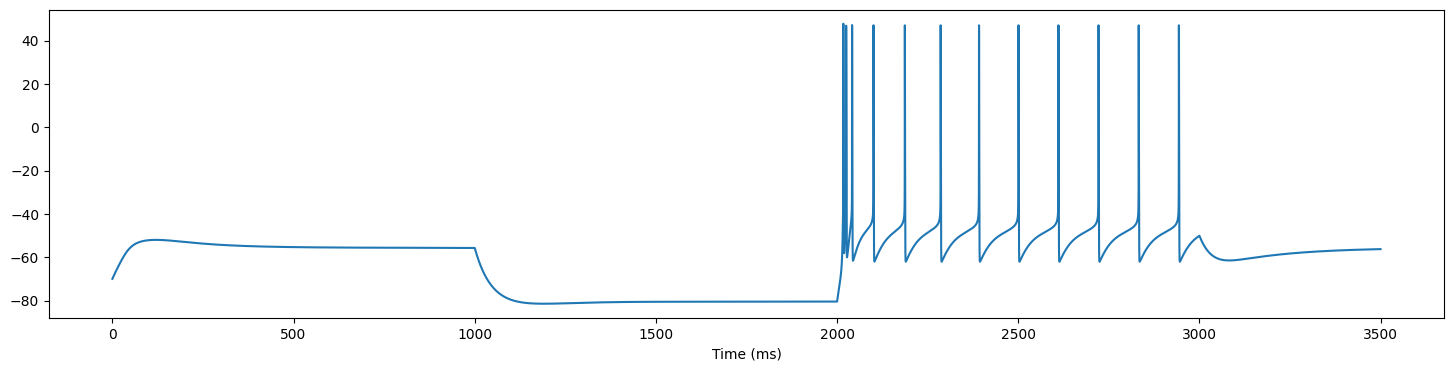

In [33]:
data = sim.allSimData
time = np.linspace(0,cfg.duration, len(data['V_soma']['cell_0']))
plt.figure(figsize=(18,4))
plt.plot(time, data['V_soma']['cell_0'])
plt.xlabel('Time (ms)')